# FD001: sensor nào thay đổi khi động cơ gần hỏng?

**Học viên:** Phan Nguyễn Mai Phương — **MSHV:** 25002711

Ở notebook 00, 30 cycle của động cơ train 1 được rút thành một dòng features. Trước khi dùng các features
để học RUL (số cycle còn lại đến khi hỏng), cần xem sensor có biến thiên hay chỉ đứng yên.

Notebook này đọc lại raw train và khảo sát theo ba câu hỏi: tuổi thọ các động cơ khác nhau thế nào,
sensor nào thay đổi theo thời gian, và chiều thay đổi có ổn định giữa các động cơ không.
Bắt đầu với **train engine 1**, sau đó kiểm tra trên cả 100 động cơ. Test được giữ riêng.

Mỗi lần chạy ghi bảng và hình vào thư mục mới `outputs/notebook01/run-*/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src/cmapss").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
RAW_PATH = ROOT / "data/raw/train_FD001.txt"
from cmapss.presentation import COLORS, apply_plot_style, style_figure
apply_plot_style()


In [2]:
import tempfile

output_root = ROOT / "outputs/notebook01"
output_root.mkdir(parents=True, exist_ok=True)
OUTPUT = Path(tempfile.mkdtemp(prefix="run-", dir=output_root))
TABLES, FIGURES = OUTPUT / "tables", OUTPUT / "figures"
TABLES.mkdir()
FIGURES.mkdir()


## 1. Đọc một động cơ trước khi gộp cả tập

Mỗi dòng là một động cơ tại một cycle (chu kỳ vận hành). Train ghi đến lúc hỏng, nên nhãn
RUL = cycle cuối − cycle hiện tại. Train engine 1 kết thúc tại cycle 192;
dòng cycle 100 vì vậy có RUL = 92. Nhãn được tạo bằng cùng hàm đã dùng ở notebook 00.

In [3]:
from cmapss.data.contracts import KEY, MEASUREMENTS, SENSORS, SETTINGS
from cmapss.data.readers import read_observations
from cmapss.data.targets import make_train_targets
from cmapss.eda import describe_measurements, select_example_engines, sensor_rul_correlations

observations = read_observations(RAW_PATH, split="train")
targets = make_train_targets(observations)
train = observations.merge(targets, on=list(KEY), how="left", validate="one_to_one")
train.query("engine_id == 1 and cycle in [1, 100, 192]")[
    ["engine_id", "cycle", "sensor_11", "sensor_12", "rul"]
]

,engine_id,cycle,sensor_11,sensor_12,rul
0,1,1,47.47,521.66,191
99,1,100,47.64,521.55,92
191,1,192,48.25,520.08,0


Hai sensor được đo tại cùng cycle, còn RUL là nhãn dùng để đối chiếu về sau.
Trước khi vẽ hình, kiểm tra kích thước, giá trị thiếu và khóa trùng trên toàn bộ train.

In [4]:
def save_table(table, filename):
    table.to_csv(TABLES / filename, index=False, float_format="%.12g", na_rep="NaN")


def show_figure(fig, filename, show=True):
    style_figure(fig)
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight", facecolor="white")
    if show:
        display(fig)
    plt.close(fig)


In [5]:
assert train["engine_id"].nunique() == 100

input_summary = pd.DataFrame([{
    "split": "train", "observations": len(train), "engines": train.engine_id.nunique(),
    "raw_columns": len(observations.columns) - 1,
    "missing_values": int(train.isna().sum().sum()),
    "duplicate_keys": int(train.duplicated(list(KEY)).sum()),
}])
schema = pd.DataFrame({"column": train.columns, "dtype": train.dtypes.astype(str).values})
save_table(input_summary, "input_summary.csv")
save_table(schema, "schema.csv")
input_summary

,split,observations,engines,raw_columns,missing_values,duplicate_keys
0,train,20631,100,26,0,0


Train có 20.631 dòng của 100 động cơ, với 26 cột gốc: id, cycle, 3 setting và 21 sensor.
Không có giá trị thiếu hoặc khóa `(split, engine_id, cycle)` bị trùng. Dữ liệu đủ điều kiện để phân tích tiếp.

## 2. Vì sao phải phân biệt tuổi thọ với RUL?

Tuổi thọ là cycle cuối: mỗi động cơ cho **một giá trị**. RUL thay đổi tại từng cycle:
train engine 1 cho 192 giá trị RUL từ 191 xuống 0.
Nếu gộp theo dòng, động cơ sống lâu có nhiều quan sát hơn và được tính nhiều lần hơn.

In [6]:
lifetimes = train.groupby("engine_id", as_index=False).agg(
    first_cycle=("cycle", "min"), last_cycle=("cycle", "max"), n_observations=("cycle", "size")
)
lifetime_summary = lifetimes.last_cycle.describe().rename_axis("statistic").reset_index(name="cycles")
rul_summary = train.rul.describe().rename_axis("statistic").reset_index(name="cycles")
save_table(lifetimes, "engine_lifetimes.csv")
save_table(lifetime_summary, "lifetime_summary.csv")
save_table(rul_summary, "rul_summary.csv")

pd.DataFrame({"tuổi thọ (mỗi động cơ)": lifetime_summary.set_index("statistic").cycles,
              "RUL (mỗi dòng)": rul_summary.set_index("statistic").cycles}).round(2)

,tuổi thọ (mỗi động cơ),RUL (mỗi dòng)
statistic,,
count,100.00,20631.00
mean,206.31,107.81
std,46.34,68.88
min,128.00,0.00
25%,177.00,51.00
50%,199.00,103.00
75%,229.25,155.00
max,362.00,361.00


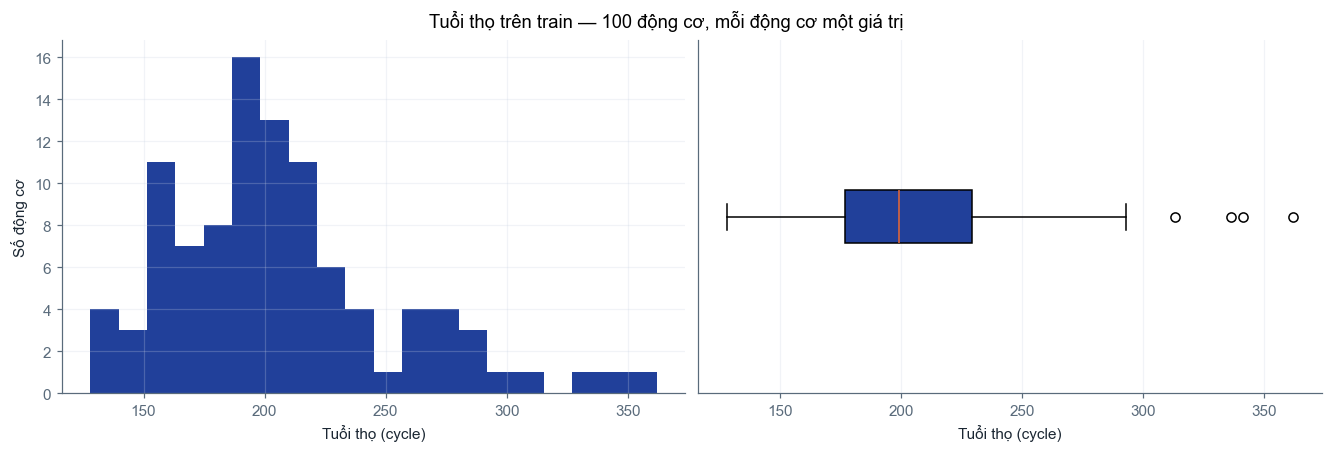

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].hist(lifetimes.last_cycle, bins=20, color=COLORS["blue"])
axes[1].boxplot(lifetimes.last_cycle, vert=False, patch_artist=True,
                boxprops={"facecolor": COLORS["blue"]})
axes[0].set(xlabel="Tuổi thọ (cycle)", ylabel="Số động cơ")
axes[1].set(xlabel="Tuổi thọ (cycle)", yticks=[])
fig.suptitle("Tuổi thọ trên train — 100 động cơ, mỗi động cơ một giá trị")
show_figure(fig, "engine_lifetimes.png")


Biểu đồ trên đếm 100 động cơ. Bây giờ chuyển sang RUL và đếm toàn bộ 20.631 dòng để thấy hai phân phối
trả lời hai câu hỏi khác nhau.

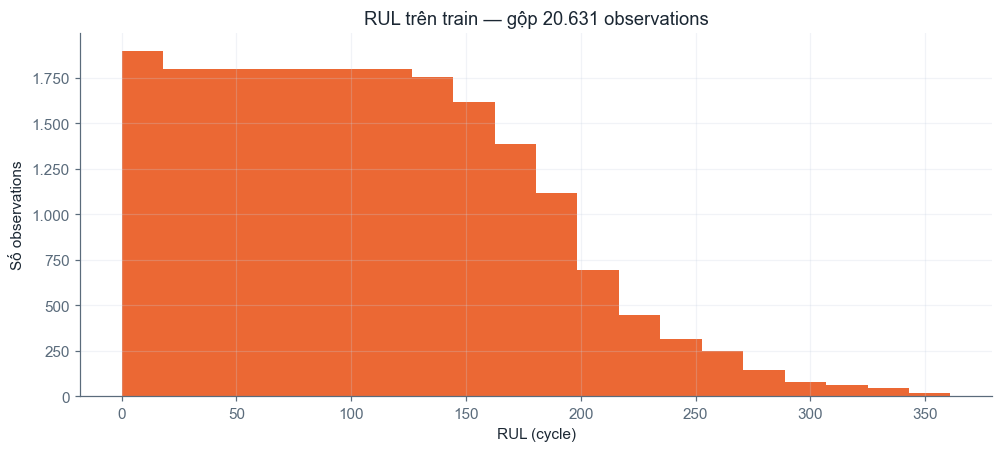

In [8]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.hist(train.rul, bins=20, color=COLORS["orange"])
ax.set(title="RUL trên train — gộp 20.631 observations",
       xlabel="RUL (cycle)", ylabel="Số observations")
show_figure(fig, "rul_distribution.png")


Tuổi thọ động cơ nằm trong khoảng 128–362 cycle, median 199 và trung bình 206,3. Phân phối lệch phải:
Q75 là 229, còn 4 động cơ có tuổi thọ trên 300 cycle (313, 336, 341, 362), nằm ngoài whisker của boxplot.
Các chuỗi này vẫn được giữ vì là dữ liệu chạy đến hỏng hợp lệ, không phải lỗi đo.

Histogram RUL đếm theo dòng dữ liệu nên động cơ sống lâu đóng góp nhiều dòng hơn. Median RUL là 103 cycle.
Số dòng giảm dần ở phía RUL lớn vì chỉ các động cơ sống lâu mới có những giá trị này.

## 3. Sensor không đổi và sensor gần như không đổi

Một cột hằng không phân biệt được các thời điểm trong FD001. Tuy nhiên, cột có nhiều giá trị trên toàn tập
vẫn có thể đứng yên trong một số động cơ. So sánh `sensor_1`, `sensor_6` và `sensor_11`
trước, rồi đếm trên toàn bộ các cột.

In [9]:
train.query("engine_id == 1").agg({
    "sensor_1": ["min", "max", "nunique"],
    "sensor_6": ["min", "max", "nunique"],
    "sensor_11": ["min", "max", "nunique"],
})

,sensor_1,sensor_6,sensor_11
min,518.67,21.61,47.03
max,518.67,21.61,48.33
nunique,1.00,1.00,80.00


In [10]:
measurement_summary = describe_measurements(train, MEASUREMENTS)
save_table(measurement_summary, "measurement_summary.csv")
constant_measurements = measurement_summary.loc[measurement_summary.is_constant, "measurement"].tolist()

measurement_summary[["measurement", "mean", "std", "min", "max", "n_unique", "is_constant"]].round(4)

,measurement,mean,std,min,max,n_unique,is_constant
0,setting_1,-0.0000,0.0022,-0.0087,0.0087,158,False
1,setting_2,0.0000,0.0003,-0.0006,0.0006,13,False
2,setting_3,100.0000,0.0000,100.0000,100.0000,1,True
3,sensor_1,518.6700,0.0000,518.6700,518.6700,1,True
4,sensor_2,642.6809,0.5001,641.2100,644.5300,310,False
5,sensor_3,1590.5231,6.1311,1571.0400,1616.9100,3012,False
6,sensor_4,1408.9338,9.0006,1382.2500,1441.4900,4051,False
7,sensor_5,14.6200,0.0000,14.6200,14.6200,1,True
8,sensor_6,21.6098,0.0014,21.6000,21.6100,2,False
9,sensor_7,553.3677,0.8851,549.8500,556.0600,513,False


Bảng trên dùng mọi dòng train. Bảng tiếp theo tách từng động cơ rồi đếm số giá trị khác nhau,
để nhận ra trường hợp biến thiên chỉ xuất hiện khi gộp nhiều động cơ.

In [11]:
long_measurements = train.melt(id_vars="engine_id", value_vars=list(MEASUREMENTS),
                               var_name="measurement", value_name="value")
within_engine = long_measurements.groupby(["engine_id", "measurement"], as_index=False).agg(
    n_observations=("value", "size"), n_unique=("value", "nunique"),
    min=("value", "min"), max=("value", "max"), mean=("value", "mean"), std=("value", "std")
)
within_engine["range"] = within_engine["max"] - within_engine["min"]
within_engine["is_constant"] = within_engine.n_unique.eq(1)
constant_counts = within_engine.groupby("measurement", as_index=False).agg(
    constant_engines=("is_constant", "sum"), total_engines=("engine_id", "size")
)
save_table(within_engine, "within_engine_variability.csv")
save_table(constant_counts, "constant_engine_counts.csv")

constant_counts[constant_counts.constant_engines > 0]

,measurement,constant_engines,total_engines
0,sensor_1,100,100
1,sensor_10,100,100
7,sensor_16,100,100
9,sensor_18,100,100
10,sensor_19,100,100
16,sensor_5,100,100
17,sensor_6,38,100
23,setting_3,100,100


Có 7 cột không đổi trên toàn tập train: `setting_3` và các sensor 1, 5, 10, 16, 18, 19.
Các cột này không cung cấp thông tin để dự đoán RUL trên FD001.

`sensor_6` chỉ nhận hai giá trị 21,60 và 21,61, đồng thời không đổi trong 38/100 động cơ.
Thống kê gộp trên toàn tập không thể hiện được đặc điểm này.
`setting_1` và `setting_2` dao động rất nhỏ quanh 0, trong khoảng ±0,0087 và ±0,0006,
phù hợp với một điều kiện vận hành của FD001.

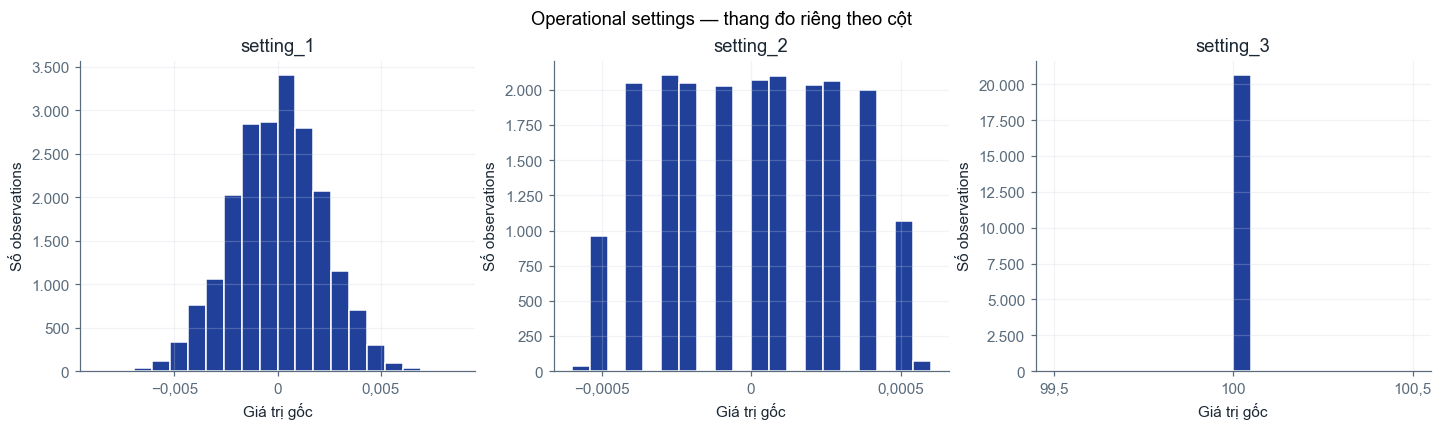

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, setting in zip(axes, SETTINGS):
    ax.hist(train[setting], bins=20, color=COLORS["blue"], edgecolor="white")
    ax.set(title=setting, xlabel="Giá trị gốc", ylabel="Số observations")
    ax.ticklabel_format(style="plain", useOffset=False, axis="x")
    ax.locator_params(axis="x", nbins=3)
fig.suptitle("Operational settings — thang đo riêng theo cột")
show_figure(fig, "settings_distributions.png")

Bốn histogram dưới đây dùng thang riêng cho mỗi sensor. So sánh hình dạng phân phối;
không so sánh trực tiếp độ lớn giữa các sensor có đơn vị khác nhau.

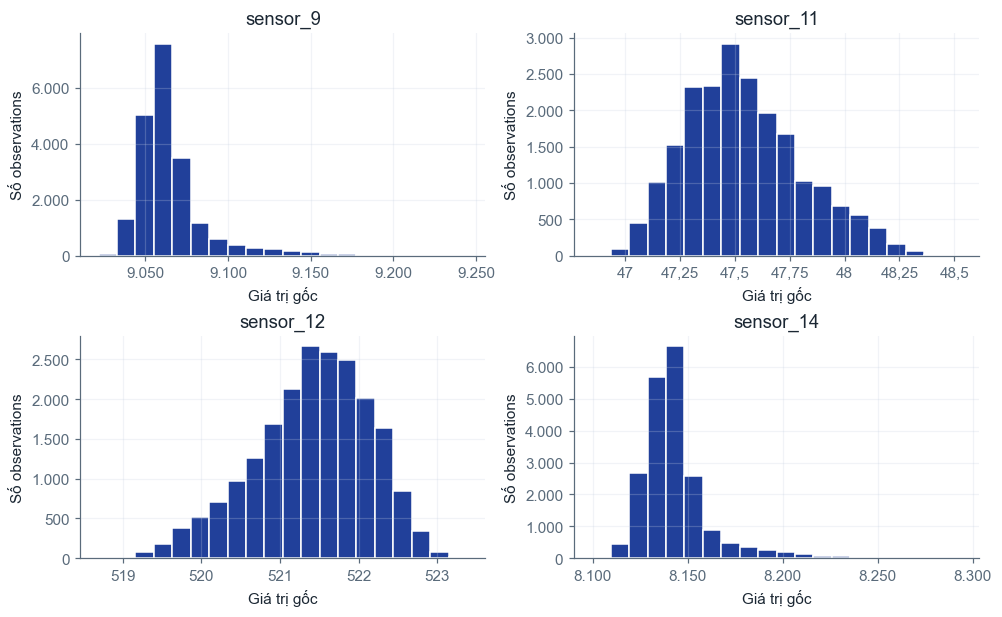

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5), layout="constrained")
for ax, sensor in zip(axes.flat, ["sensor_9", "sensor_11", "sensor_12", "sensor_14"]):
    ax.hist(train[sensor], bins=20, color=COLORS["blue"], edgecolor="white")
    ax.set(title=sensor, xlabel="Giá trị gốc", ylabel="Số observations")
    ax.ticklabel_format(style="plain", useOffset=False, axis="x")
show_figure(fig, "selected_sensor_distributions.png")

Phân phối của `sensor_11` và `sensor_12` gần dạng chuông, hơi lệch về một phía.
Ở `sensor_9` và `sensor_14`, phần lớn giá trị tập trung bên trái và có đuôi dài bên phải.
Chẳng hạn, `sensor_9` đạt 9.245 trong khi median là 9.061. Đuôi phân phối đến từ các động cơ
có giá trị tăng mạnh cuối vòng đời, được xem tiếp ở mục 4.

## 4. Phân phối chưa cho biết thứ tự thời gian

Histogram của sensor 11 có thể gồm cả giai đoạn đầu và cuối đời. Cần vẽ theo cycle để thấy giá trị
tăng, giảm hay chỉ dao động quanh một mức. Trước hết xem lại engine 1, rồi dùng ba động cơ gần
Q25, median và Q75 về tuổi thọ để đối chiếu.

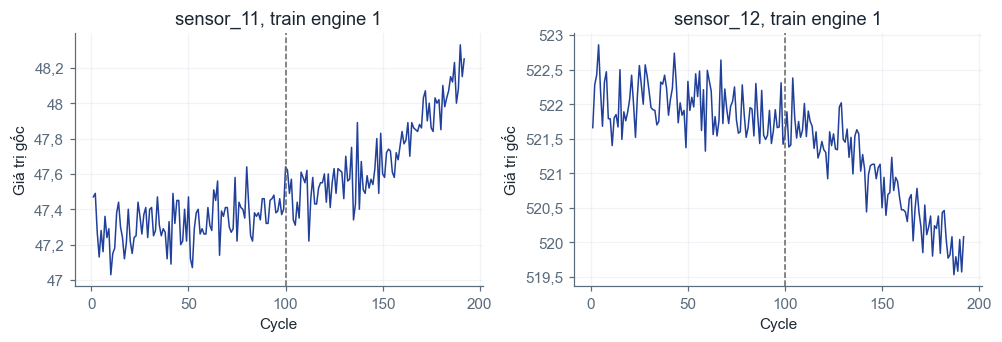

In [14]:
engine1 = train.query("engine_id == 1")
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
for ax, sensor in zip(axes, ["sensor_11", "sensor_12"]):
    ax.plot(engine1.cycle, engine1[sensor], linewidth=1)
    ax.axvline(100, color="0.4", linestyle="--", linewidth=1)
    ax.set(title=f"{sensor}, train engine 1", xlabel="Cycle", ylabel="Giá trị gốc")
show_figure(fig, "engine1_sensor_trends.png")

Đường gạch đánh dấu cycle 100 đã dùng ở notebook 00. Đồ thị này dùng cả lịch sử train để mô tả xu hướng;
features tại cycle 100 vẫn chỉ được lấy từ hiện tại và quá khứ. Không dùng phần đường bên phải để dự đoán
cho chính thời điểm 100.

In [15]:
examples = select_example_engines(lifetimes)
save_table(examples, "example_engines.csv")
example_ids = examples.engine_id.drop_duplicates().tolist()
colors = list(COLORS.values())[:len(example_ids)]
examples


,quantile,target_lifetime,engine_id,last_cycle
0,0.25,177.00,87,178
1,0.50,199.00,26,199
2,0.75,229.25,75,229


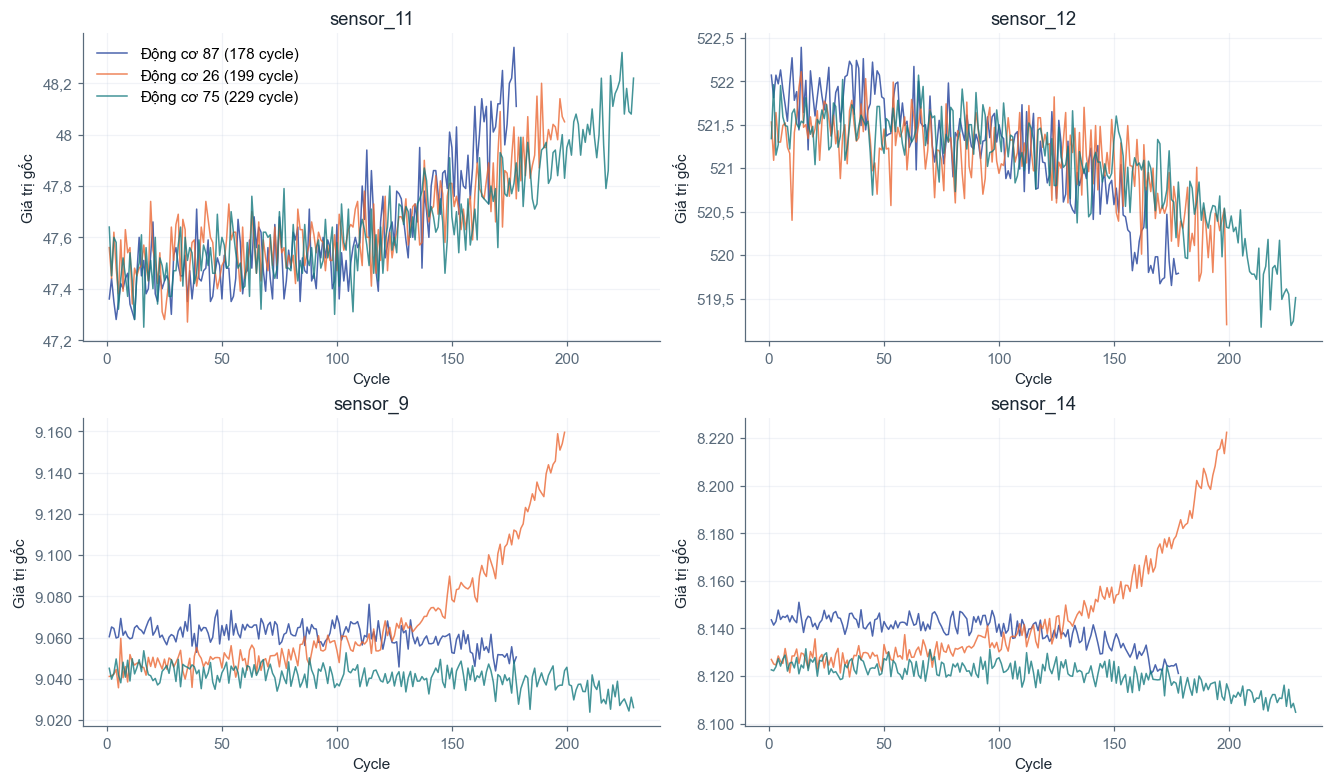

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, sensor in zip(axes.flat, ["sensor_11", "sensor_12", "sensor_9", "sensor_14"]):
    for engine_id, color in zip(example_ids, colors):
        engine = train[train.engine_id.eq(engine_id)]
        ax.plot(engine.cycle, engine[sensor], color=color, linewidth=1, alpha=0.8,
                label=f"Động cơ {engine_id} ({engine.cycle.max()} cycle)")
    ax.set(title=sensor, xlabel="Cycle", ylabel="Giá trị gốc")
axes[0, 0].legend(frameon=False)
show_figure(fig, "selected_sensor_trajectories.png")

Ở ba động cơ 87, 26 và 75, `sensor_11` gần như ổn định trong khoảng 100 cycle đầu rồi tăng về cuối đời;
`sensor_12` giảm dần. Hai sensor này có xu hướng nhất quán trên cả ba động cơ.

Với `sensor_9` và `sensor_14`, động cơ 26 có giá trị tăng mạnh ở cuối, còn hai động cơ kia gần như
đi ngang hoặc giảm nhẹ. Các sensor vì vậy không cùng biến đổi theo một hướng khi động cơ xuống cấp.
Ba động cơ chưa đủ để kết luận cho toàn tập; mục 5 kiểm tra trên cả 100 động cơ.

## 5. Xu hướng có ổn định trên cả 100 động cơ không?

Spearman rho đo liên hệ đơn điệu theo thứ hạng. Rho âm giữa sensor và RUL nghĩa là sensor thường tăng
khi RUL giảm. Trước hết, heatmap xem các sensor có mang thông tin giống nhau không; sau đó tính
sensor–RUL **riêng từng động cơ**.

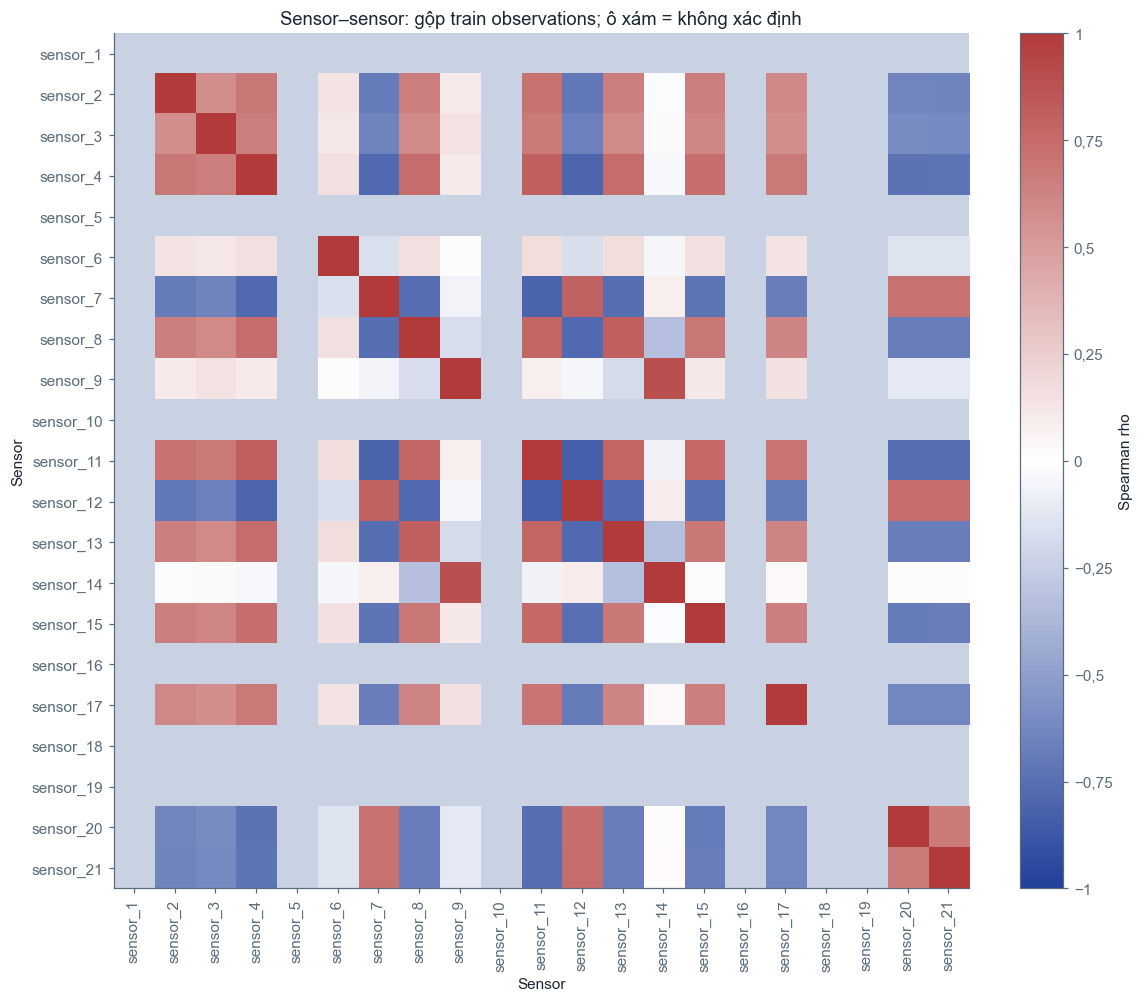

In [17]:
from matplotlib.colors import LinearSegmentedColormap

sensor_correlation = train[list(SENSORS)].corr(method="spearman")
sensor_correlation.index.name = "sensor"
save_table(sensor_correlation.reset_index(), "sensor_spearman_pooled.csv")
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ax.set_facecolor(COLORS["grid"])
cmap = LinearSegmentedColormap.from_list("sensor", [COLORS["blue"], COLORS["white"], COLORS["red"]])
image = ax.imshow(sensor_correlation, vmin=-1, vmax=1, cmap=cmap)
fig.colorbar(image, ax=ax, label="Spearman rho")
ax.set(xticks=range(len(SENSORS)), xticklabels=SENSORS,
       yticks=range(len(SENSORS)), yticklabels=SENSORS)
ax.tick_params(axis="x", labelrotation=90)
ax.grid(False)
ax.set(title="Sensor–sensor: gộp train observations; ô xám = không xác định",
       xlabel="Sensor", ylabel="Sensor")
show_figure(fig, "sensor_spearman_pooled.png")


Có 6 sensor hằng cho các ô xám vì không tính được tương quan. Trong số còn lại, sensor 2, 3, 4, 8, 11,
13, 15, 17 tương quan cùng chiều với nhau; sensor 7, 12, 20, 21 biến đổi theo chiều ngược lại.
Ví dụ, `sensor_11` và `sensor_12` có rho = −0,83.

`sensor_9` và `sensor_14` tương quan mạnh với nhau (rho = 0,89), nhưng ít liên hệ với các sensor khác.
Một số sensor mang thông tin trùng nhau; đây là đặc điểm cần lưu ý nếu thử chọn đặc trưng.

Tương quan sensor–RUL được tính riêng cho từng động cơ, cho tối đa 100 hệ số mỗi sensor.
Median và độ phân tán của các hệ số cho biết mức liên hệ có ổn định giữa các động cơ hay không.
Cách tính này cho các động cơ trọng số như nhau, bất kể chiều dài chuỗi.
Nếu sensor không đổi trong một động cơ, hệ số tương quan không xác định (NaN).

In [18]:
correlations = sensor_rul_correlations(train, SENSORS)
save_table(correlations, "sensor_rul_by_engine.csv")
correlation_summary = correlations.groupby("sensor")["rho"].describe().rename(
    columns={"count": "defined_engines", "25%": "q25", "50%": "median", "75%": "q75"}
).reindex(SENSORS)
correlation_summary["undefined_engines"] = 100 - correlation_summary.defined_engines
save_table(correlation_summary.reset_index(), "sensor_rul_summary.csv")

correlation_summary[["defined_engines", "q25", "median", "q75"]].dropna().round(3)

,defined_engines,q25,median,q75
sensor,,,,
sensor_2,100.0,-0.707,-0.671,-0.625
sensor_3,100.0,-0.678,-0.637,-0.585
sensor_4,100.0,-0.804,-0.784,-0.759
sensor_6,62.0,-0.192,-0.126,-0.083
sensor_7,100.0,0.715,0.774,0.802
sensor_8,100.0,-0.816,-0.768,-0.603
sensor_9,100.0,-0.911,-0.739,0.193
sensor_11,100.0,-0.848,-0.819,-0.780
sensor_12,100.0,0.748,0.808,0.833


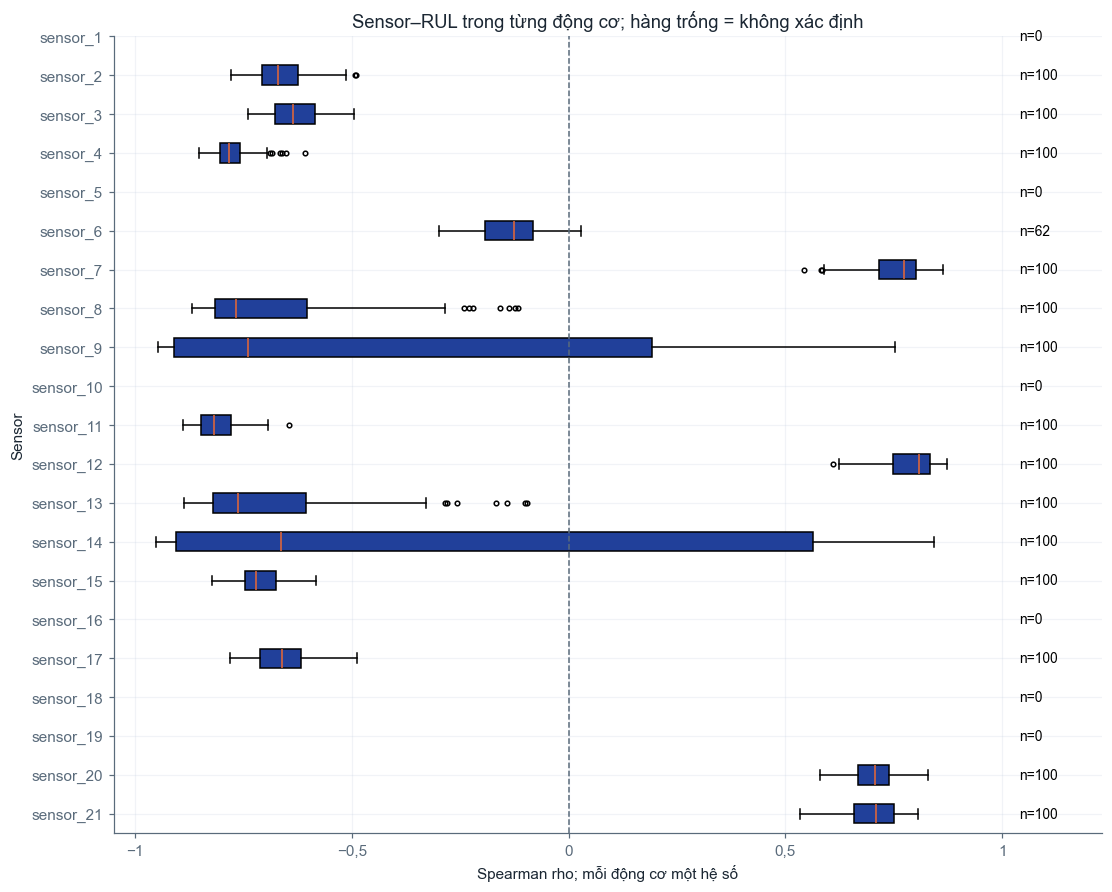

In [19]:
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
valid_correlations = correlations[correlations.defined]
for position, sensor in enumerate(SENSORS):
    values = valid_correlations.loc[valid_correlations.sensor.eq(sensor), "rho"]
    if len(values):
        ax.boxplot(values, positions=[position], vert=False, widths=0.5,
                   patch_artist=True, boxprops={"facecolor": COLORS["blue"]},
                   flierprops={"markersize": 3})
    count = int(correlation_summary.loc[sensor, "defined_engines"])
    ax.text(1.04, position, f"n={count}", va="center", fontsize=9)
ax.axvline(0, color=COLORS["muted"], linewidth=1, linestyle="--")
ax.set(yticks=range(len(SENSORS)), yticklabels=SENSORS,
       xlim=(-1.05, 1.23), xticks=[-1, -0.5, 0, 0.5, 1],
       xlabel="Spearman rho; mỗi động cơ một hệ số", ylabel="Sensor",
       title="Sensor–RUL trong từng động cơ; hàng trống = không xác định")
ax.invert_yaxis()
show_figure(fig, "sensor_rul_by_engine.png")


`sensor_11` có liên hệ với RUL mạnh và ổn định nhất: median rho −0,819, Q25–Q75 từ −0,848 đến −0,780.
Hai sensor tiếp theo là `sensor_12` (0,808) và `sensor_4` (−0,784). Khoảng phân bố hẹp cho thấy
mức liên hệ tương đối nhất quán giữa các động cơ.

Median của `sensor_9` và `sensor_14` lần lượt là −0,739 và −0,663, nhưng Q75 dương (0,193 và 0,563).
Chiều liên hệ đổi dấu giữa các động cơ, phù hợp với quỹ đạo ở mục 4.
`sensor_6` chỉ tính được hệ số ở 62 động cơ và có median gần 0 (−0,126).

Ở ví dụ engine 1, chỉ cần lấy hai dãy sensor 11 và RUL để tính một hệ số.
Bảng 100 động cơ ở trên cho biết ví dụ này có đại diện cho xu hướng chung hay không.

In [20]:
engine1[["sensor_11", "sensor_12", "rul"]].corr(method="spearman").loc[
    ["sensor_11", "sensor_12"], ["rul"]
]

,rul
sensor_11,-0.841144
sensor_12,0.827460


## 6. Lưu bảng, hình và điều kiện chạy

Các biểu đồ chính ở trên đủ để theo dõi lập luận. Hai cell tiếp theo xuất thêm histogram và quỹ đạo
cho đủ 21 sensor, thành ba trang mỗi loại. Chúng được lưu để tra cứu, không in thêm các trang dài vào notebook.

In [21]:
for page in range(3):
    sensors = SENSORS[page * 7:(page + 1) * 7]
    fig, axes = plt.subplots(4, 2, figsize=(12, 12), layout="constrained")
    for ax, sensor in zip(axes.flat, sensors):
        ax.hist(train[sensor], bins=20, color=COLORS["blue"], edgecolor="white")
        suffix = " (hằng)" if sensor in constant_measurements else ""
        ax.set(title=sensor + suffix, xlabel="Giá trị gốc", ylabel="Số observations")
        ax.ticklabel_format(style="plain", useOffset=False, axis="x")
        ax.locator_params(axis="x", nbins=4)
    axes.flat[-1].set_visible(False)
    fig.suptitle(f"Phân phối sensor — trang {page + 1}/3, thang đo riêng theo ô")
    show_figure(fig, f"sensor_distributions_{page + 1}.png", show=False)

In [22]:
# ba trang quỹ đạo của đủ 21 sensor, chỉ lưu file
for page in range(3):
    sensors = SENSORS[page * 7:(page + 1) * 7]
    fig, axes = plt.subplots(4, 2, figsize=(12, 12), layout="constrained")
    for ax, sensor in zip(axes.flat, sensors):
        for engine_id, color in zip(example_ids, colors):
            engine = train[train.engine_id.eq(engine_id)].sort_values("cycle")
            ax.plot(engine.cycle, engine[sensor], color=color, linewidth=1, alpha=0.8,
                    label=f"Engine {engine_id}: {engine.cycle.max()} cycles")
        ax.set(title=sensor, xlabel="Cycle", ylabel="Giá trị gốc")
        ax.ticklabel_format(style="plain", useOffset=False, axis="y")
    legend_ax = axes.flat[-1]
    legend_ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", frameon=False)
    fig.suptitle(f"Quỹ đạo sensor — trang {page + 1}/3; engines chọn theo tuổi thọ")
    show_figure(fig, f"sensor_trajectories_{page + 1}.png", show=False)

In [23]:
from importlib.metadata import version
import hashlib
import json
import platform

run_info = {
    "author": "Phan Nguyễn Mai Phương", "student_id": "25002711",
    "input": "data/raw/train_FD001.txt",
    "input_sha256": hashlib.sha256(RAW_PATH.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "versions": {name: version(name) for name in
                 ("cmapss-rul", "pandas", "numpy", "scipy", "matplotlib", "seaborn", "ipykernel")},
}

In [24]:
run_info.update({
    "sample_std_ddof": 1, "quantile_interpolation": "linear", "histogram_bins": 20,
    "test_data_used": False, "observations": len(train), "engines": len(lifetimes),
    "example_engine_ids": example_ids, "constant_measurements": constant_measurements,
    "tables": sorted(path.name for path in TABLES.glob("*.csv")),
    "figures": sorted(path.name for path in FIGURES.glob("*.png")),
})
(OUTPUT / "run_info.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Kết quả lần chạy: {OUTPUT.relative_to(ROOT)}")

Kết quả lần chạy: outputs\notebook01\run-pvg8uubm


Sensor 11 và 12 là hai ví dụ có xu hướng rõ; sensor 9 và 14 cho thấy chiều thay đổi có thể khác giữa
các động cơ. Bảy cột hằng và sensor 6 gần như hằng cũng cần được nhận diện trước khi xây dựng mô hình.

EDA này dùng toàn bộ train để mô tả dữ liệu. Nếu dùng kết quả để chọn features, phải thực hiện lại việc
chọn trong từng training fold để tránh rò rỉ dữ liệu. Notebook 02 sẽ kiểm tra chênh lệch đầu/cuối đời;
mô hình chính vẫn dùng 126 features từ đủ 21 sensor.